In [17]:
%load_ext autoreload
%autoreload 2
from run_survey_on_llm import WVSLLMBaselineRunner
from dataloader import WVSDataLoader
loader = WVSDataLoader("/home/tchakrab/gb-scratch/wvs/data/WVS_Time_Series_1981-2022_csv_v5_0.csv")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# Config(ish)
country_1 = "USA"
country_2 = "IND"
wave_1 = 6
wave_2 = 6
run_llm_1 = True
run_llm_2 = True

In [20]:
runner_1 = WVSLLMBaselineRunner(country=country_1, wave_number=wave_1, df=loader.df)
runner_1.load_data()
prompts, mapping = runner_1.create_prompts()
print(f"Number of prompts for {country_1}: {len(prompts)}")
# # Run llm for country 1
# if run_llm_1:
#     raw_path = runner_1.run_llm(prompts, mapping)
#     parsed_path = runner_1.parse_llm_responses(raw_path)
# accuracy_1 = runner_1.compute_accuracy()
# runner_1.save_accuracy_results(accuracy_1)

Loading Data...
Creating prompts...
Filtered questions: 194 out of 905 questions have ≥50% response rate
Number of prompts for USA: 1000


In [22]:
mapping

{"### Person Description:\nYou are a 60 year old female from USA born in 1951 and living in ?. You do not live with your parents, in terms of a partner you are married and have 5 children. Your education level is recorded as middle level. You are employed full-time and work primarily as ?. In terms of family savings, during the past year your family spent savings and borrowed money. In terms of social class you are working class and your income level is low income.\n\n### Questions\n#### Question 1:\n\nQuestion: Please provide the numeric CoW country code.\nOptions: \n\n#### Question 2:\n\nQuestion: Indicate how important the following aspect is in your life. Would you say it is very important, rather important, not very important, or not important at all?\nAspect: Family\nOptions: 1 Very important, 2 Rather important, 3 Not very important, 4 Not at all important, -1 Don't know, -2 No answer, -4 Not asked, -5 Missing; Not available\n\n#### Question 3:\n\nQuestion: For the following asp

In [4]:
runner_2 = WVSLLMBaselineRunner(country=country_2, wave_number=wave_2, df=loader.df)
runner_2.load_data()
prompts, mapping = runner_2.create_prompts()
print(f"Number of prompts for {country_2}: {len(prompts)}")
# Run llm for country 2
if run_llm_2:
    raw_path = runner_2.run_llm(prompts, mapping)
    parsed_path = runner_2.parse_llm_responses(raw_path)
accuracy_2 = runner_2.compute_accuracy()
runner_2.save_accuracy_results(accuracy_2)

Loading Data...
Creating prompts...
Filtered questions: 140 out of 679 questions have ≥50% response rate
Number of prompts for IND: 700
Accuracy results saved to: /home/tchakrab/gb-scratch/wvs/results/accuracy_results_IND_6.json


'/home/tchakrab/gb-scratch/wvs/results/accuracy_results_IND_6.json'

In [5]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Load accuracy results for both countries
with open(f'/home/tchakrab/gb-scratch/wvs/results/accuracy_results_{country_1}_{wave_1}.json', 'r') as f:
    accuracy_1 = json.load(f)

with open(f'/home/tchakrab/gb-scratch/wvs/results/accuracy_results_{country_2}_{wave_2}.json', 'r') as f:
    iaccuracy = json.load(f)

In [6]:
variable_lookup_df = pd.read_csv('/home/tchakrab/gb-scratch/wvs/data/WVS_Time_Series_Vars.csv')
var_to_title = variable_lookup_df.set_index('Variable')['Title'].to_dict()

# Extract question accuracies
questions_1 = accuracy_1['question_accuracies']
questions_2 = accuracy_2['question_accuracies']

# Only questions present in BOTH countries
common_questions = set(questions_1.keys()) & set(questions_2.keys())
common_questions = sorted(list(common_questions))

# Create data for heatmap
heatmap_data = []
question_labels = []

for question in common_questions:
    acc_1 = questions_1[question]['accuracy']
    acc_2 = questions_2[question]['accuracy']

    # Prefer first country's question text, fallback to second country's
    question_text = questions_1[question].get(
        'question_text',
        questions_2[question].get('question_text', question)
    )

    # Truncate long questions
    if question_text and len(question_text) > 60:
        question_text = question_text[:57] + "..."

    question_labels.append(f"{question}: {var_to_title.get(question)}")
    heatmap_data.append([acc_1, acc_2])

heatmap_data = np.array(heatmap_data)

print(f"Found {len(common_questions)} questions in both countries")
print(f"Overall {country_1} accuracy: {accuracy_1['overall_accuracy']:.3f}")
print(f"Overall {country_2} accuracy: {accuracy_2['overall_accuracy']:.3f}")

Found 132 questions in both countries
Overall USA accuracy: 0.350
Overall IND accuracy: 0.368


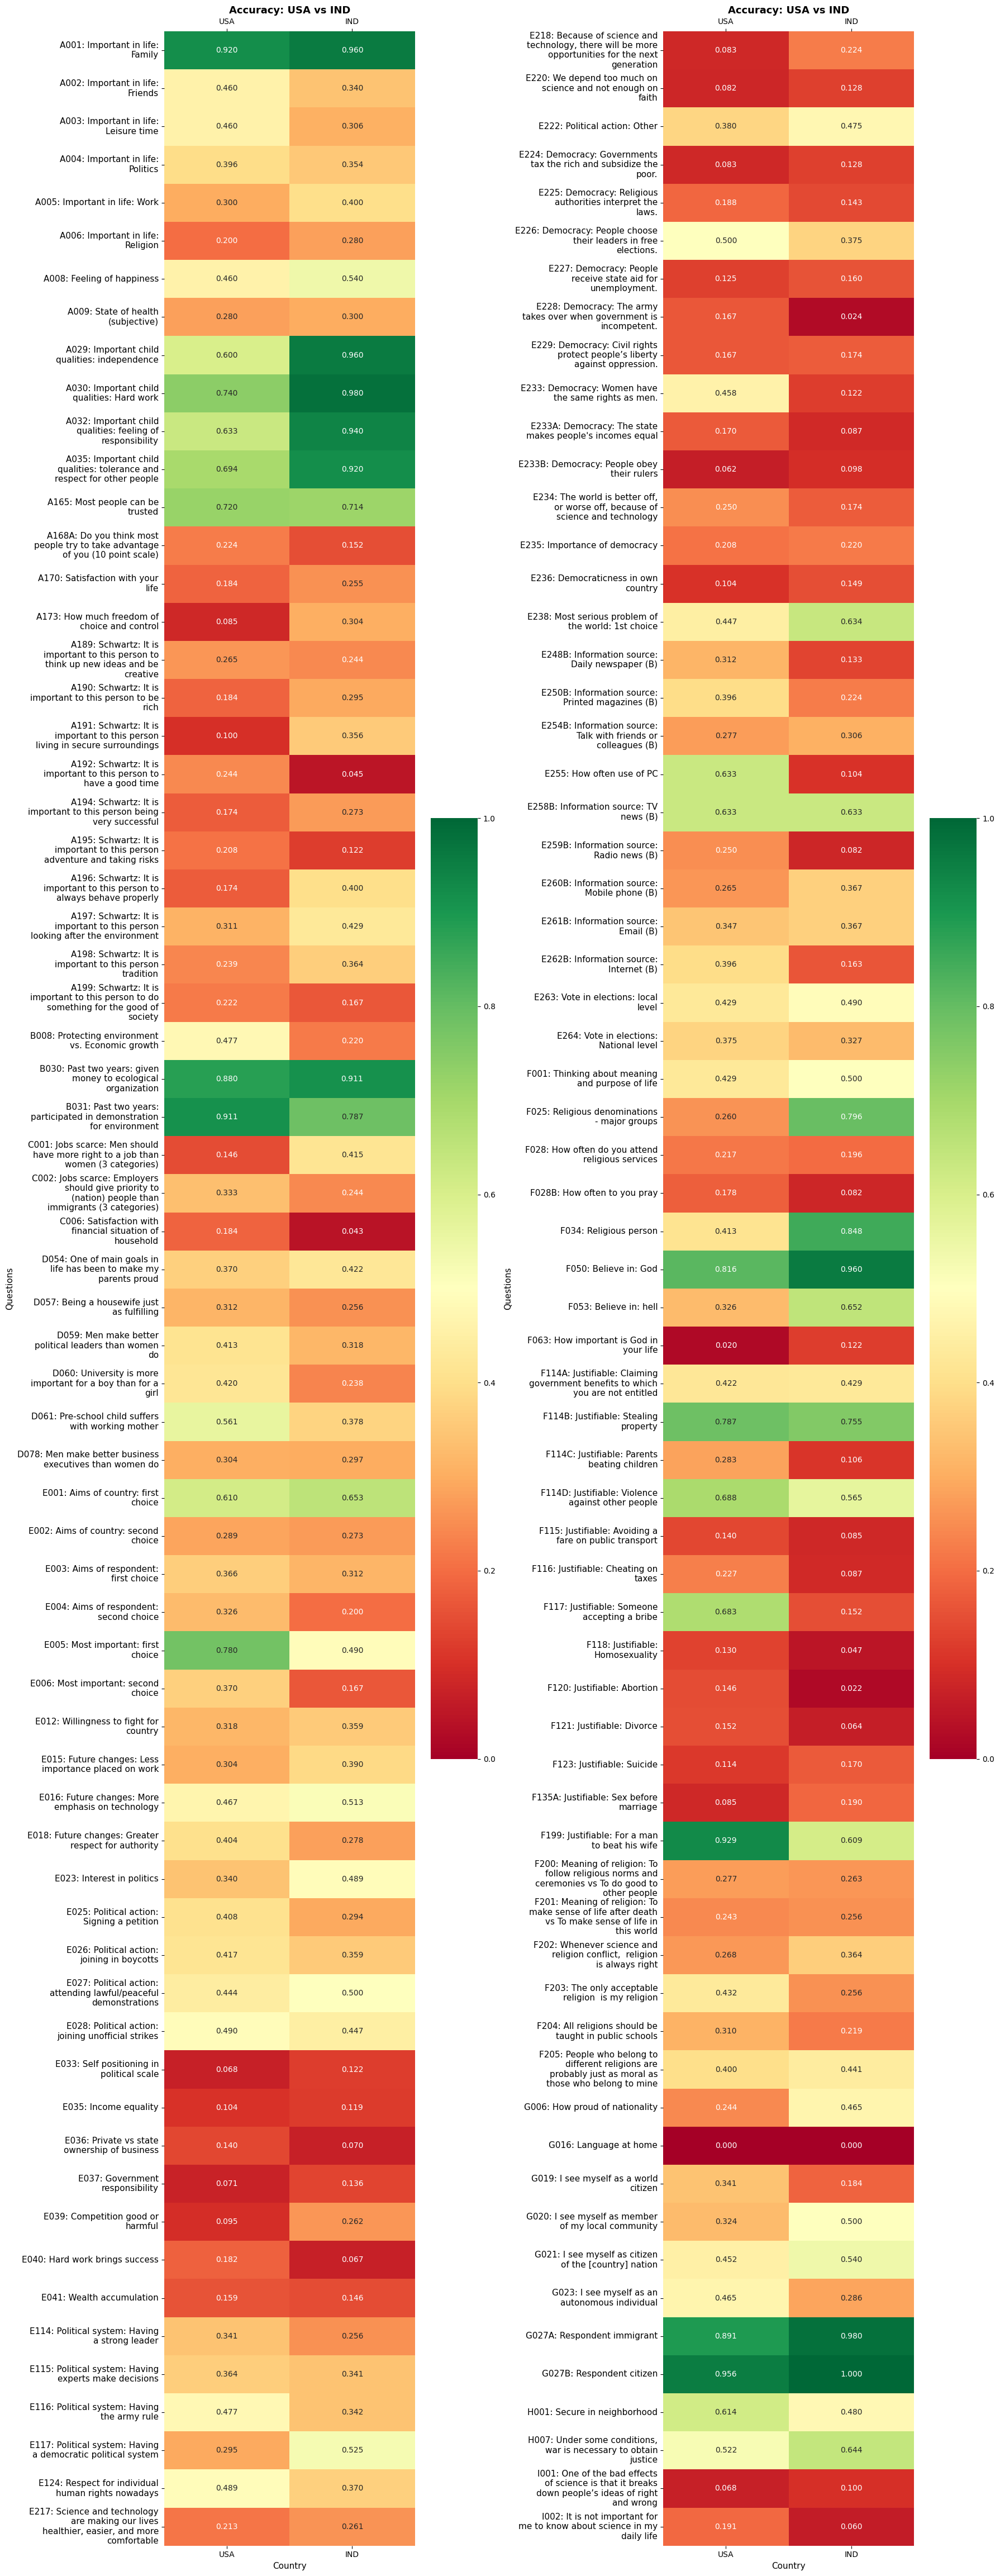

In [7]:
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def wrap_labels(labels, width=40):
    return ['\n'.join(textwrap.wrap(lbl, width=width)) for lbl in labels]

wrapped_labels = wrap_labels(question_labels, width=30)

df_heatmap = pd.DataFrame(
    heatmap_data,
    columns=[f'{country_1}', f'{country_2}'],
    index=wrapped_labels
)

n = len(df_heatmap)
mid = n // 2

df_left = df_heatmap.iloc[:mid]
df_right = df_heatmap.iloc[mid:]

fig, axes = plt.subplots(
    ncols=2,
    figsize=(18, max(12, n * 0.35)),
    sharey=False
)

for ax, df_part, title_suffix in zip(
    axes,
    [df_left, df_right],
    ['(Questions 1)', '(Questions 2)']
):
    sns.heatmap(
        df_part,
        annot=True,
        fmt='.3f',
        cmap='RdYlGn',
        cbar=True,
        vmin=0,
        vmax=1,
        ax=ax
    )
    ax.set_title(f'Accuracy: {country_1} vs {country_2}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Country', fontsize=11)
    ax.set_ylabel('Questions', fontsize=11)
    ax.tick_params(axis='y', labelsize=11)

    ax.tick_params(
    axis='x',
    top=True,
    bottom=True,
    labeltop=True,
    labelbottom=True
)

plt.tight_layout()
plt.show()


In [8]:
# Summary statistics comparison
diff_data = heatmap_data[:, 0] - heatmap_data[:, 1]  # Country 1 - Country 2

print("=== ACCURACY COMPARISON SUMMARY ===")
print(f"Questions analyzed: {len(common_questions)}")
print(f"{country_1} overall accuracy: {accuracy_1['overall_accuracy']:.3f}")
print(f"{country_2} overall accuracy: {accuracy_2['overall_accuracy']:.3f}")
print(f"Difference ({country_1} - {country_2}): {accuracy_1['overall_accuracy'] - accuracy_2['overall_accuracy']:.3f}")
print()

print("=== QUESTION-LEVEL ANALYSIS ===")
print(f"Questions where {country_1} > {country_2}: {np.sum(diff_data > 0)}")
print(f"Questions where {country_2} > {country_1}: {np.sum(diff_data < 0)}")
print(f"Questions with equal accuracy: {np.sum(diff_data == 0)}")
print()

# Top questions where Country 1 performs better
country_1_better_idx = np.argsort(diff_data)[-5:][::-1]
print(f"Top 5 questions where {country_1} performs better:")
for i in country_1_better_idx:
    if diff_data[i] > 0:
        print(f"  {question_labels[i][:50]}...")
        print(f"    {country_1}: {heatmap_data[i, 0]:.3f}, {country_2}: {heatmap_data[i, 1]:.3f}, Diff: +{diff_data[i]:.3f}")
print()

# Top questions where Country 2 performs better  
country_2_better_idx = np.argsort(diff_data)[:5]
print(f"Top 5 questions where {country_2} performs better:")
for i in country_2_better_idx:
    if diff_data[i] < 0:
        print(f"  {question_labels[i][:50]}...")
        print(f"    {country_1}: {heatmap_data[i, 0]:.3f}, {country_2}: {heatmap_data[i, 1]:.3f}, Diff: {diff_data[i]:.3f}")

=== ACCURACY COMPARISON SUMMARY ===
Questions analyzed: 132
USA overall accuracy: 0.350
IND overall accuracy: 0.368
Difference (USA - IND): -0.018

=== QUESTION-LEVEL ANALYSIS ===
Questions where USA > IND: 65
Questions where IND > USA: 65
Questions with equal accuracy: 2

Top 5 questions where USA performs better:
  F117: Justifiable: Someone accepting a bribe...
    USA: 0.683, IND: 0.152, Diff: +0.531
  E255: How often use of PC...
    USA: 0.633, IND: 0.104, Diff: +0.528
  E233: Democracy: Women have the same rights as men...
    USA: 0.458, IND: 0.122, Diff: +0.336
  F199: Justifiable: For a man to beat his wife...
    USA: 0.929, IND: 0.609, Diff: +0.320
  E005: Most important: first choice...
    USA: 0.780, IND: 0.490, Diff: +0.291

Top 5 questions where IND performs better:
  F025: Religious denominations - major groups...
    USA: 0.260, IND: 0.796, Diff: -0.536
  F034: Religious person...
    USA: 0.413, IND: 0.848, Diff: -0.435
  A029: Important child qualities: independenc